# Big Data Analytics: Project 2
## Digital Advertising Budget Optimizer: *"Where should we spend the next Rs. 1 million?"*

> **All data in this notebook is SIMULATED.** The platform parameters (CPM, CTR, conversion rate, order value,
> diminishing-returns strength) are illustrative assumptions, not measured industry benchmarks and not data from any real company.
> The recommendation therefore shows the **method**; it is not evidence about real campaign performance.
> To use it for real, replace the simulated table with an authorised campaign export that has the same 12 columns.



## 1. Setup: the data generator and the benchmark harness
The next two cells write two small helper files (`adsim.py`, `bench.py`) so the benchmark can run each engine in a fresh process.

In [1]:
%%writefile adsim.py
"""Synthetic digital-advertising data generator for Project 2.

EVERYTHING HERE IS SIMULATED. The platform parameters below are illustrative
assumptions chosen so the funnel looks plausible (CTR, CPC, CVR, ROAS in
believable ranges). They are NOT measured industry benchmarks and NOT data from
any real company. Any recommendation computed from this data therefore reflects
these assumptions; it demonstrates the method, not real-world performance.

Design choices
--------------
* One record = one slice of a platform's daily budget for a campaign/segment.
  The platform-day budget D is fixed regardless of N, so 10 thousand and 10
  million records describe the SAME spend; more records just means finer slices.
  That makes the Pandas/MapReduce/Spark comparison fair across sizes.
* Diminishing returns: conversion rate falls as the platform's daily budget
  rises above its usual level (CVR is multiplied by f ** -sat, where f = D/base).
  This is what lets a budget optimizer learn that more money is not always better.
"""
import numpy as np
import pandas as pd

PLATFORMS = ["Facebook", "Instagram", "Google", "TikTok", "YouTube"]
# illustrative assumptions (see module docstring)
BASE_DAILY_BUDGET = np.array([30000, 35000, 40000, 20000, 15000], float)  # Rs / day
CPM = np.array([250, 320, 900, 180, 220], float)       # Rs per 1,000 impressions
# --- Calibration from Project 1 (optional, on by default) -------------------------------------------
# Project 1's cleaned social-media file has median engagement per post of Facebook 34, Instagram 46,
# TikTok 56. Normalised by their mean (45.3) this gives a RELATIVE engagement level, used here to
# scale the click-through assumption of those three platforms. Google and YouTube are not in Project 1,
# so they keep the plain assumptions. Caveats: Project 1 data is unverified/likely synthetic, and
# engagement per post is not a click-through rate; this only sets the *relative ordering* of CTRs.
CALIBRATE_FROM_PROJECT1 = True
P1_MEDIAN_ENGAGEMENT = {"Facebook": 34.0, "Instagram": 46.0, "TikTok": 56.0}
_p1_mean = sum(P1_MEDIAN_ENGAGEMENT.values()) / 3
P1_CTR_INDEX = {k: v / _p1_mean for k, v in P1_MEDIAN_ENGAGEMENT.items()}
CTR = np.array([.011, .010, .035, .008, .005])         # clicks / impression (assumed)
if CALIBRATE_FROM_PROJECT1:
    CTR = CTR * np.array([P1_CTR_INDEX["Facebook"], P1_CTR_INDEX["Instagram"], 1.0, P1_CTR_INDEX["TikTok"], 1.0])
CVR = np.array([.022, .020, .035, .011, .010])         # conversions / click
AOV = np.array([4500, 5200, 4800, 3800, 4200], float)  # Rs revenue per conversion
SAT = np.array([.20, .30, .15, .35, .25])              # diminishing-returns exponent (TRUE value)

CAMPAIGNS = ["Eid_Collection", "Summer_Lawn", "Winter_Sale", "Bridal_Launch", "Back_to_School",
             "Black_Friday", "New_Arrivals", "Clearance", "Brand_Awareness", "Menswear_Push",
             "Kids_Range", "Loyalty_Offer"]
CAMP_CVR = np.array([1.25, 1.10, 1.05, 1.20, 0.95, 1.30, 1.00, 1.15, 0.60, 0.90, 0.85, 1.10])
CITIES = ["Karachi", "Lahore", "Islamabad", "Rawalpindi", "Faisalabad", "Multan", "Peshawar", "Quetta"]
CITY_P = np.array([.28, .26, .12, .08, .08, .07, .07, .04])
CITY_CVR = np.array([1.05, 1.05, 1.15, 1.00, .95, .92, .90, .85])
CITY_AOV = np.array([1.05, 1.05, 1.12, 1.00, .95, .93, .92, .88])
DEVICES = ["Mobile", "Desktop", "Tablet"]
DEVICE_P = np.array([.72, .22, .06])
DEVICE_CTR = np.array([1.00, .85, .80])
DEVICE_CVR = np.array([.90, 1.30, 1.05])
AGES = ["18-24", "25-34", "35-44", "45-54", "55+"]
# audience mix by platform (rows follow PLATFORMS) and age multipliers on CTR
AGE_P = np.array([[.12, .30, .28, .19, .11],
                  [.28, .38, .20, .10, .04],
                  [.14, .34, .27, .17, .08],
                  [.46, .34, .13, .05, .02],
                  [.22, .33, .24, .14, .07]])
AGE_CTR = np.array([[.9, 1.1, 1.0, 0.95, 0.9],
                    [1.1, 1.05, 0.95, 0.9, 0.8],
                    [0.9, 1.1, 1.05, 1.0, 0.9],
                    [1.15, 1.0, 0.9, 0.8, 0.7],
                    [1.0, 1.05, 1.0, 0.95, 0.9]])
GENDERS = ["Female", "Male"]
GENDER_P = np.array([[.58, .42], [.62, .38], [.50, .50], [.60, .40], [.45, .55]])
GENDER_CVR = np.array([[1.08, .92], [1.10, .90], [1.0, 1.0], [1.05, .95], [.95, 1.05]])

START = pd.Timestamp("2025-01-01")
N_DAYS = 365
# sale windows lift conversion rate (not budget), as promotions do
SALE_WINDOWS = [("2025-03-10", "2025-03-30"), ("2025-06-01", "2025-06-06"), ("2025-11-20", "2025-11-30")]

COLUMNS = ["date", "campaign", "platform", "impressions", "clicks", "spend", "conversions",
           "revenue", "age", "gender", "city", "device"]


def _sale_boost(n_days):
    b = np.ones(n_days)
    for a, z in SALE_WINDOWS:
        i0, i1 = (pd.Timestamp(a) - START).days, (pd.Timestamp(z) - START).days
        if 0 <= i0 < n_days:
            b[i0:min(i1 + 1, n_days)] = 1.35
    return b


def generate_arrays(n, seed=42, daily_budget=None, n_days=N_DAYS):
    """Return a dict of numpy arrays (category columns as integer codes).

    daily_budget: optional array of 5 constant daily budgets (Rs) per platform,
    used for A/B-style 'what if we spent X' simulations. Default: historical
    budgets drawn around BASE_DAILY_BUDGET with random day-to-day multiples.
    """
    rng = np.random.default_rng(seed)
    P = len(PLATFORMS)
    plat_p = BASE_DAILY_BUDGET / BASE_DAILY_BUDGET.sum()
    plat = rng.choice(P, size=n, p=plat_p).astype(np.int8)
    day = rng.integers(0, n_days, size=n).astype(np.int16)

    # platform-day budget multiple f and budget D
    if daily_budget is None:
        f_grid = np.exp(rng.normal(0, 0.5, size=(P, n_days)))
        D_grid = BASE_DAILY_BUDGET[:, None] * f_grid
    else:
        D_grid = np.repeat(np.asarray(daily_budget, float)[:, None], n_days, axis=1)
        f_grid = D_grid / BASE_DAILY_BUDGET[:, None]
    key = plat.astype(np.int64) * n_days + day
    w = rng.lognormal(0, 0.6, size=n)
    sumw = np.bincount(key, weights=w, minlength=P * n_days)
    spend = D_grid.ravel()[key] * w / sumw[key]

    camp = rng.integers(0, len(CAMPAIGNS), size=n).astype(np.int8)
    city = rng.choice(len(CITIES), size=n, p=CITY_P).astype(np.int8)
    dev = rng.choice(len(DEVICES), size=n, p=DEVICE_P).astype(np.int8)
    # per-platform categorical draws (vectorised by inverse-CDF)
    age = np.empty(n, np.int8); gen = np.empty(n, np.int8)
    for p in range(P):
        m = plat == p
        k = int(m.sum())
        age[m] = rng.choice(len(AGES), size=k, p=AGE_P[p])
        gen[m] = rng.choice(2, size=k, p=GENDER_P[p])

    imp = np.maximum(np.round(spend / CPM[plat] * 1000 * np.exp(rng.normal(0, .1, n))), 0).astype(np.int64)
    ctr = np.minimum(CTR[plat] * AGE_CTR[plat, age] * DEVICE_CTR[dev], .5)
    clicks = rng.binomial(imp, ctr)
    sale = _sale_boost(n_days)[day]
    f = f_grid.ravel()[key]
    cvr = np.minimum(CVR[plat] * CAMP_CVR[camp] * CITY_CVR[city] * DEVICE_CVR[dev] * GENDER_CVR[plat, gen]
                     * sale * f ** (-SAT[plat]), .5)
    conv = rng.binomial(clicks, cvr)
    revenue = conv * AOV[plat] * CITY_AOV[city] * np.exp(rng.normal(-0.02, .2, n))
    return dict(day=day, camp=camp, plat=plat, imp=imp, clicks=clicks, spend=np.round(spend, 2),
                conv=conv, revenue=np.round(revenue, 2), age=age, gen=gen, city=city, dev=dev)


def to_frame(a, start=0, stop=None):
    """Convert (a slice of) the arrays into the 12-column DataFrame."""
    s = slice(start, stop)
    dates = np.array([(START + pd.Timedelta(days=int(d))).strftime("%Y-%m-%d") for d in range(N_DAYS)], dtype=object)
    return pd.DataFrame({
        "date": dates[a["day"][s]],
        "campaign": np.array(CAMPAIGNS, dtype=object)[a["camp"][s]],
        "platform": np.array(PLATFORMS, dtype=object)[a["plat"][s]],
        "impressions": a["imp"][s], "clicks": a["clicks"][s], "spend": a["spend"][s],
        "conversions": a["conv"][s], "revenue": a["revenue"][s],
        "age": np.array(AGES, dtype=object)[a["age"][s]],
        "gender": np.array(GENDERS, dtype=object)[a["gen"][s]],
        "city": np.array(CITIES, dtype=object)[a["city"][s]],
        "device": np.array(DEVICES, dtype=object)[a["dev"][s]],
    })[COLUMNS]


def generate(n, seed=42, daily_budget=None, n_days=N_DAYS):
    a = generate_arrays(n, seed, daily_budget, n_days)
    return to_frame(a)


def write_csv(n, path, seed=42, chunk=1_000_000):
    """Generate n records and write them to CSV in chunks (memory friendly)."""
    a = generate_arrays(n, seed)
    for i, start in enumerate(range(0, n, chunk)):
        to_frame(a, start, min(start + chunk, n)).to_csv(path, mode="w" if i == 0 else "a",
                                                          header=(i == 0), index=False)

Writing adsim.py


In [2]:
%%writefile bench.py
"""Pandas vs MapReduce-style vs Spark on the SAME task (Project 2).

Task: read the CSV and compute per-platform totals of impressions, clicks, spend,
conversions, revenue and record count (the input to every KPI: CTR, CPC, CPA,
conversion rate, ROAS).

* Pandas      - read_csv + groupby.
* MapReduce   - a faithful MapReduce-STYLE job in pure Python: input splits by byte
                range (like HDFS blocks), map -> in-mapper combiner -> shuffle by key
                -> reduce. It is NOT Hadoop; it models the programming model.
* Spark       - PySpark local mode. Defined here and used in the Colab notebook.
                (Not runnable in the build sandbox: PySpark could not be installed.)
Each engine runs in a fresh process so peak memory is honest.
"""
import json
import os
import resource
import subprocess
import sys
import time
from multiprocessing import Pool

ROOT = os.path.dirname(os.path.abspath(__file__))   # works on any machine (including Colab)
NUMS = ["impressions", "clicks", "spend", "conversions", "revenue"]
CAT = ["campaign", "platform", "age", "gender", "city", "device"]


# ---------------------------------------------------------------- Pandas
def run_pandas(path):
    import pandas as pd
    t0 = time.perf_counter()
    df = pd.read_csv(path, dtype={c: "category" for c in CAT})
    t_load = time.perf_counter() - t0
    t1 = time.perf_counter()
    g = df.groupby("platform", observed=True)[NUMS].sum()
    g["records"] = df.groupby("platform", observed=True).size()
    t_agg = time.perf_counter() - t1
    return {"load_s": t_load, "agg_s": t_agg, "total_s": t_load + t_agg,
            "result": {p: [float(v) for v in row] for p, row in g[NUMS + ["records"]].iterrows()}}


# ---------------------------------------------------------------- MapReduce-style
def _map_split(args):
    """MAP: read one byte-range 'input split'; emit (platform, values); combine locally."""
    path, start, end = args
    acc = {}
    with open(path, "rb") as f:
        if start == 0:
            f.readline()                       # header
        else:
            f.seek(start - 1); f.readline()    # align to the next full line (Hadoop LineRecordReader rule)
        pos = f.tell()
        while pos < end:
            line = f.readline()
            if not line:
                break
            c = line.split(b",")
            key = c[2].decode()
            v = acc.get(key)
            if v is None:
                v = acc[key] = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
            v[0] += int(c[3]); v[1] += int(c[4]); v[2] += float(c[5])
            v[3] += int(c[6]); v[4] += float(c[7]); v[5] += 1
            pos = f.tell()
    return acc


def run_mapreduce(path, workers=None, n_splits=16):
    workers = workers or os.cpu_count()
    size = os.path.getsize(path)
    step = -(-size // n_splits)
    splits = [(path, i * step, min((i + 1) * step, size)) for i in range(n_splits) if i * step < size]
    t0 = time.perf_counter()
    with Pool(workers) as pool:
        mapped = pool.map(_map_split, splits)             # MAP (+ combiner)
    t_map = time.perf_counter() - t0
    t1 = time.perf_counter()
    shuffled = {}                                          # SHUFFLE: group partial results by key
    for part in mapped:
        for k, v in part.items():
            shuffled.setdefault(k, []).append(v)
    reduced = {k: [sum(col) for col in zip(*vals)] for k, vals in shuffled.items()}   # REDUCE
    t_red = time.perf_counter() - t1
    return {"map_s": t_map, "shuffle_reduce_s": t_red, "total_s": t_map + t_red, "workers": workers,
            "splits": len(splits), "result": reduced}


# ---------------------------------------------------------------- Spark (used in Colab)
def run_spark(path):
    from pyspark.sql import SparkSession, functions as F
    t0 = time.perf_counter()
    spark = (SparkSession.builder.master("local[*]").appName("project2")
             .config("spark.driver.memory", "4g").config("spark.sql.shuffle.partitions", "8").getOrCreate())
    t_start = time.perf_counter() - t0                      # JVM / session start-up
    t1 = time.perf_counter()
    # explicit schema: inferSchema makes Spark read the whole file twice, which would unfairly penalise it
    schema = ("date string, campaign string, platform string, impressions long, clicks long, spend double, "
              "conversions long, revenue double, age string, gender string, city string, device string")
    df = spark.read.csv(path, header=True, schema=schema)
    rows = (df.groupBy("platform").agg(*[F.sum(c).alias(c) for c in NUMS], F.count("*").alias("records")).collect())
    t_job = time.perf_counter() - t1
    spark.stop()
    return {"startup_s": t_start, "job_s": t_job, "total_s": t_job,
            "result": {r["platform"]: [float(r[c]) for c in NUMS] + [float(r["records"])] for r in rows}}


# ---------------------------------------------------------------- harness
def _child(engine, path):
    """Run one engine and measure its peak memory by SAMPLING live RSS of this process plus all its
    child processes (MapReduce workers, Spark's JVM). The old ru_maxrss method is wrong when the
    parent is large (e.g. a Colab kernel): a child inherits the parent's high-water mark."""
    import threading
    import psutil
    me = psutil.Process()
    base = me.memory_info().rss
    peak = [base]; stop = threading.Event()

    def sample():
        while not stop.is_set():
            try:
                tot = me.memory_info().rss + sum(c.memory_info().rss for c in me.children(recursive=True))
                peak[0] = max(peak[0], tot)
            except psutil.Error:
                pass
            stop.wait(0.05)

    th = threading.Thread(target=sample, daemon=True); th.start()
    res = {"pandas": run_pandas, "mapreduce": run_mapreduce, "spark": run_spark}[engine](path)
    stop.set(); th.join()
    res["peak_rss_mb"] = peak[0] / 1e6
    res["baseline_rss_mb"] = base / 1e6
    print("@@" + json.dumps(res))


def _run(engine, path, timeout=1500):
    t = time.perf_counter()
    p = subprocess.run([sys.executable, __file__, "--child", engine, path], capture_output=True, text=True,
                       timeout=timeout)
    wall = time.perf_counter() - t
    lines = [l for l in p.stdout.splitlines() if l.startswith("@@")]
    if p.returncode != 0 or not lines:
        return {"failed": True, "returncode": p.returncode, "stderr": p.stderr[-300:], "wall_s": wall}
    r = json.loads(lines[-1][2:]); r["wall_s"] = wall
    return r


def main(sizes=(10_000, 100_000, 1_000_000, 10_000_000), engines=("pandas", "mapreduce")):
    # NOTE: the harness stays tiny and generates data in a separate process. A forked child inherits its
    # parent's peak-memory high-water mark, so a heavy parent would corrupt every memory measurement.
    work = os.path.join(ROOT, "bench_files"); os.makedirs(work, exist_ok=True)
    os.makedirs(os.path.join(ROOT, "outputs"), exist_ok=True)
    out = []
    for n in sizes:
        path = f"{work}/ads_{n}.csv"
        t = time.perf_counter()
        subprocess.run([sys.executable, "-c",
                        f"import sys; sys.path.insert(0, {ROOT!r}); import adsim; adsim.write_csv({n}, {path!r}, seed=7)"],
                       check=True)
        t_gen = time.perf_counter() - t
        row = {"rows": n, "file_mb": round(os.path.getsize(path) / 1e6, 1), "generate_s": round(t_gen, 1)}
        results = {}
        for e in engines:
            runs = [_run(e, path) for _ in range(3)]            # 3 repeats; report the median run
            bad = [r for r in runs if r.get("failed")]
            if bad:
                results[e] = bad[0]; row[e] = {"failed": True, "detail": bad[0]["stderr"]}
                continue
            runs.sort(key=lambda r: r["total_s"]); r = runs[1]; results[e] = r
            row[e] = {k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items() if k != "result"}
            row[e]["all_total_s"] = [round(x["total_s"], 3) for x in runs]
        # correctness: do the engines agree?
        if all(not results[e].get("failed") for e in engines) and len(engines) > 1:
            ref = results[engines[0]]["result"]; ok = True; worst = 0.0
            for e in engines[1:]:
                for k, v in ref.items():
                    o = results[e]["result"][k]
                    for a, b in zip(v, o):
                        d = abs(a - b) / max(abs(a), 1.0); worst = max(worst, d)
            row["engines_agree"] = worst < 1e-9; row["max_rel_diff"] = worst
        out.append(row)
        print(json.dumps(row), flush=True)
        os.remove(path)
        json.dump(out, open(os.path.join(ROOT, "outputs", "benchmark_results.json"), "w"), indent=2)
    return out


if __name__ == "__main__":
    if len(sys.argv) == 4 and sys.argv[1] == "--child":
        _child(sys.argv[2], sys.argv[3])
    else:
        main()

Writing bench.py


In [3]:
import os, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
import adsim
COL = dict(Facebook="#3b5bdb", Instagram="#d6336c", Google="#2f9e44", TikTok="#f08c00", YouTube="#e03131")
PLAT = adsim.PLATFORMS

## 2. Data: 12 columns, 100,000 simulated records
Columns: `date, campaign, platform, impressions, clicks, spend, conversions, revenue, age, gender, city, device`.
One row = one slice of a platform's daily budget for one campaign and audience segment (a **data object** = one ad record).
Each platform-day budget is fixed, so 10 thousand or 10 million records describe the *same* spend, only at finer detail.

In [4]:
df = adsim.generate(100_000, seed=42)
df["date"] = pd.to_datetime(df["date"])
print("Rows, columns:", df.shape, "| dates:", df.date.min().date(), "to", df.date.max().date())
print("Missing cells:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
display(df.dtypes)
display(df.head())
display(df.describe().T.round(2))

Rows, columns: (100000, 12) | dates: 2025-01-01 to 2025-12-31
Missing cells: 0 | duplicate rows: 0


,0
date,datetime64[ns]
campaign,object
platform,object
impressions,int64
clicks,int64
spend,float64
conversions,int64
revenue,float64
age,object
gender,object


,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device
0,2025-12-30,Back_to_School,TikTok,12225,121,1765.30,2,6608.30,25-34,Female,Lahore,Mobile
1,2025-12-09,Kids_Range,Instagram,345,8,111.17,1,4614.37,18-24,Female,Lahore,Mobile
2,2025-12-18,Brand_Awareness,TikTok,3260,33,615.53,0,0.00,18-24,Male,Lahore,Mobile
3,2025-12-12,Kids_Range,Google,200,2,172.83,0,0.00,18-24,Male,Islamabad,Desktop
4,2025-11-19,Winter_Sale,Facebook,3524,17,926.26,1,5479.54,55+,Male,Islamabad,Tablet


,count,mean,min,25%,50%,75%,max,std
date,100000,2025-07-01 16:48:43.200000,2025-01-01 00:00:00,2025-04-01 00:00:00,2025-07-01 00:00:00,2025-10-01 00:00:00,2025-12-31 00:00:00,NaN
impressions,100000.0,1860.47224,10.0,592.0,1199.0,2313.0,67060.0,2168.197146
clicks,100000.0,20.49259,0.0,8.0,14.0,26.0,453.0,21.303757
spend,100000.0,573.700493,8.51,247.99,419.97,715.315,12440.94,533.59243
conversions,100000.0,0.4802,0.0,0.0,0.0,1.0,19.0,0.873748
revenue,100000.0,2320.001264,0.0,0.0,0.0,4211.8125,135488.73,4414.172154


## 3. Marketing KPIs
| KPI | Formula |
|---|---|
| CTR | clicks / impressions |
| CPC | spend / clicks |
| CPA | spend / conversions |
| Conversion rate | conversions / clicks |
| ROAS | revenue / spend |

**Rule:** compute every ratio from the **summed** totals (ratio of sums). Averaging row-level ratios gives wrong answers
because small rows count as much as big ones.

,records,spend,revenue,CTR_%,CPC,CPA,ConvRate_%,ROAS
platform,,,,,,,,
Facebook,21326.0,11902619.96,4.088335e+07,0.79,31.61,1347.98,2.35,3.43
Instagram,24902.0,14012298.41,4.910279e+07,0.99,32.23,1522.74,2.12,3.50
Google,28807.0,16792352.88,1.161202e+08,3.42,26.12,714.42,3.66,6.92
TikTok,14237.0,8308830.12,1.978223e+07,0.98,18.20,1639.47,1.11,2.38
YouTube,10728.0,6353947.95,6.111533e+06,0.48,45.84,4490.42,1.02,0.96


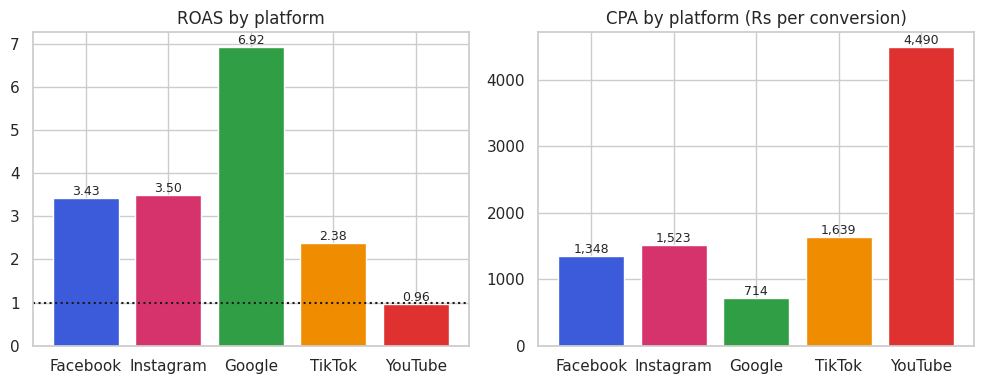

In [5]:
def kpis(g):
    s = g[["impressions","clicks","spend","conversions","revenue"]].sum()
    return pd.Series({"records": len(g), "spend": s.spend, "revenue": s.revenue,
        "CTR_%": 100*s.clicks/s.impressions, "CPC": s.spend/s.clicks, "CPA": s.spend/s.conversions,
        "ConvRate_%": 100*s.conversions/s.clicks, "ROAS": s.revenue/s.spend})

plat = df.groupby("platform").apply(kpis, include_groups=False).loc[PLAT]
display(plat.round(2))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, m, t in [(ax[0], "ROAS", "ROAS by platform"), (ax[1], "CPA", "CPA by platform (Rs per conversion)")]:
    a.bar(plat.index, plat[m], color=[COL[p] for p in plat.index]); a.set_title(t)
    for i, v in enumerate(plat[m]): a.text(i, v, f"{v:,.2f}" if m=="ROAS" else f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
ax[0].axhline(1, color="k", ls=":")  # break-even
plt.tight_layout(); plt.show()

In [6]:
camp = df.groupby("campaign").apply(kpis, include_groups=False).sort_values("ROAS", ascending=False)
display(camp[["records","spend","revenue","CTR_%","CPA","ROAS"]].round(2))
for dim in ["device","city","age","gender"]:
    print(f"\nROAS by {dim}:"); print(df.groupby(dim).apply(kpis, include_groups=False)["ROAS"].sort_values(ascending=False).round(2).to_string())

,records,spend,revenue,CTR_%,CPA,ROAS
campaign,,,,,,
Black_Friday,8284.0,4706812.03,23654141.58,1.11,967.48,5.03
Eid_Collection,8210.0,4667181.47,23150714.51,1.11,977.62,4.96
Bridal_Launch,8431.0,4875216.83,22514057.76,1.09,1042.83,4.62
Clearance,8442.0,4850168.22,21563840.26,1.10,1086.02,4.45
Loyalty_Offer,8158.0,4724999.90,20634956.93,1.11,1107.59,4.37
Summer_Lawn,8351.0,4789099.23,20666125.17,1.10,1115.82,4.32
Winter_Sale,8406.0,4839143.74,19845855.85,1.11,1179.13,4.10
New_Arrivals,8412.0,4793882.17,18952333.05,1.11,1222.93,3.95
Back_to_School,8512.0,4862468.76,17968632.36,1.12,1306.06,3.70



ROAS by device:
device
Desktop    4.77
Mobile     3.86
Tablet     3.61

ROAS by city:
city
Islamabad     5.06
Karachi       4.26
Lahore        4.23
Rawalpindi    3.75
Faisalabad    3.50
Multan        3.27
Peshawar      3.14
Quetta        2.88

ROAS by age:
age
35-44    4.32
25-34    4.22
45-54    4.11
55+      3.94
18-24    3.49

ROAS by gender:
gender
Female    4.10
Male      3.97


## 4. The Big Data simulation: 10 thousand to 10 million records, three engines
**Same task for every engine:** read the CSV and total impressions, clicks, spend, conversions, revenue and record count per platform
(the input to every KPI above).

| Engine | What it is here |
|---|---|
| **Pandas** | `read_csv` + `groupby` on one machine |
| **MapReduce** | A MapReduce-**style** job in pure Python: byte-range input splits, map, in-mapper combiner, shuffle, reduce. It models the programming model; it is **not** Hadoop (no cluster, no HDFS, no job-startup or disk-shuffle cost) |
| **Spark** | PySpark in local mode (all cores of this one machine), used automatically when PySpark is installed |

Each engine runs in a **fresh process** (so peak memory is honest) and **3 times** (median reported). The harness also checks that
all engines return the **same totals**.

In [7]:
import importlib.util, sys
try:
    import pyspark                      # preinstalled on Colab
except ImportError:
    !pip install -q pyspark
    import pyspark
ENGINES = ("pandas", "mapreduce", "spark")
RUN_10M = True        # set False on a small machine; it writes a ~760 MB CSV and takes a few minutes
SIZES = (10_000, 100_000, 1_000_000) + ((10_000_000,) if RUN_10M else ())
import bench
res = bench.main(sizes=SIZES, engines=ENGINES)

{"rows": 10000, "file_mb": 0.9, "generate_s": 2.2, "pandas": {"load_s": 0.057, "agg_s": 0.007, "total_s": 0.065, "peak_rss_mb": 110.121, "baseline_rss_mb": 15.606, "wall_s": 1.24, "all_total_s": [0.046, 0.065, 0.084]}, "mapreduce": {"map_s": 0.084, "shuffle_reduce_s": 0.0, "total_s": 0.084, "workers": 2, "splits": 16, "peak_rss_mb": 46.043, "baseline_rss_mb": 15.544, "wall_s": 0.225, "all_total_s": [0.07, 0.084, 0.086]}, "spark": {"startup_s": 14.765, "job_s": 11.718, "total_s": 11.718, "peak_rss_mb": 669.946, "baseline_rss_mb": 15.528, "wall_s": 27.861, "all_total_s": [10.95, 11.718, 12.839]}, "engines_agree": true, "max_rel_diff": 1.8634619465300152e-15}
{"rows": 100000, "file_mb": 8.2, "generate_s": 1.5, "pandas": {"load_s": 0.21, "agg_s": 0.013, "total_s": 0.224, "peak_rss_mb": 133.501, "baseline_rss_mb": 15.589, "wall_s": 1.084, "all_total_s": [0.204, 0.224, 0.232]}, "mapreduce": {"map_s": 0.241, "shuffle_reduce_s": 0.0, "total_s": 0.241, "workers": 2, "splits": 16, "peak_rss_mb":

,mapreduce,pandas,spark
rows,,,
10000,0.08,0.06,11.72
100000,0.24,0.22,12.87
1000000,2.10,2.12,16.62
10000000,25.00,20.11,39.91


,mapreduce,pandas,spark
rows,,,
10000,46.0,110.0,670.0
100000,46.0,134.0,793.0
1000000,46.0,325.0,932.0
10000000,46.0,2434.0,1145.0


Engines agree on every total: True


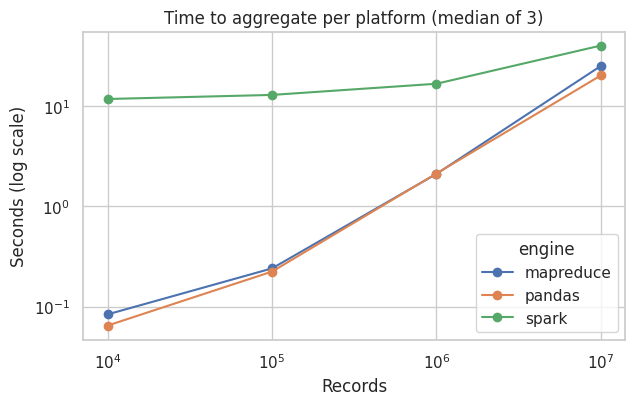

In [8]:
rows = []
for r in res:
    for e in ENGINES:
        d = r.get(e, {})
        if d.get("failed"): rows.append(dict(rows=r["rows"], engine=e, total_s=None, peak_mb=None, note="FAILED")); continue
        rows.append(dict(rows=r["rows"], file_mb=r["file_mb"], engine=e, total_s=d["total_s"],
                         peak_mb=d["peak_rss_mb"], note=("startup %.1fs excluded" % d["startup_s"]) if "startup_s" in d else ""))
bt = pd.DataFrame(rows)
display(bt.pivot(index="rows", columns="engine", values="total_s").round(2).rename_axis(None, axis=1))
display(bt.pivot(index="rows", columns="engine", values="peak_mb").round(0).rename_axis(None, axis=1))
print("Engines agree on every total:", all(r.get("engines_agree", False) for r in res))
ax = bt.pivot(index="rows", columns="engine", values="total_s").plot(marker="o", logx=True, logy=True, figsize=(7, 4))
ax.set(title="Time to aggregate per platform (median of 3)", xlabel="Records", ylabel="Seconds (log scale)"); plt.show()

### How to read the benchmark (read this before quoting any number)
* These timings are for **one machine**. Spark and MapReduce are built for **clusters**; on a single machine at ≤10 million rows
  a lean single-process tool such as Pandas or a streaming job is often as fast or faster, because Spark pays JVM start-up and
  scheduling overhead and real Hadoop MapReduce pays job start-up and disk shuffles that this simulation does not model.
* The pattern to look for is **how time and memory grow**: Pandas holds the whole table in memory (memory grows with rows);
  a streaming MapReduce job keeps only running totals (memory stays flat); Spark spills to disk and spreads across machines.
* The need for Spark depends on data size, the operation, hardware and service requirements, not on a fixed row count.

## 5. Response curves: what happens when you spend more?
For each platform we measure **ROAS on each day** against that day's **spend**. If ROAS falls as spend rises, the extra
money is working less hard (diminishing returns). We fit  `ROAS = a * spend^(-s)`, so revenue = `a * spend^(1-s)`.
A bigger `s` means the platform saturates faster.

,s,s_lo,s_hi,d_p5,d_p95,days,true_s (simulator)
Facebook,0.194,0.140,0.245,11676.122,66890.362,365.0,0.20
Instagram,0.269,0.205,0.329,15831.130,77558.954,365.0,0.30
Google,0.139,0.101,0.180,18601.796,86727.862,365.0,0.15
TikTok,0.326,0.235,0.408,8752.700,48681.704,365.0,0.35
YouTube,0.317,0.214,0.442,7421.735,37316.940,351.0,0.25


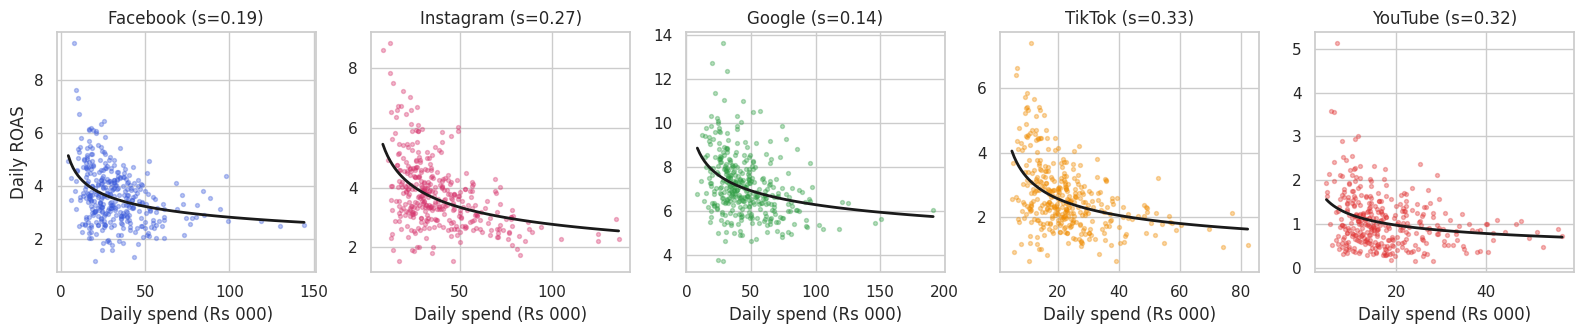

In [9]:
pdays = df.groupby(["platform","date"]).agg(spend=("spend","sum"), revenue=("revenue","sum")).reset_index()
pdays = pdays[(pdays.spend > 0) & (pdays.revenue > 0)].copy(); pdays["roas"] = pdays.revenue / pdays.spend

def fit_curve(g):
    s = float(np.clip(-np.polyfit(np.log(g.spend), np.log(g.roas), 1)[0], 0.01, 0.95))
    a = g.revenue.sum() / np.sum(g.spend ** (1 - s))      # calibrate level to total revenue
    return a, s

def fit_all(data, boot=0, seed=0):
    rng, out = np.random.default_rng(seed), {}
    for p in PLAT:
        g = data[data.platform == p]; a, s = fit_curve(g); lo = hi = np.nan
        if boot:
            ss = [fit_curve(g.iloc[rng.integers(0, len(g), len(g))])[1] for _ in range(boot)]
            lo, hi = np.percentile(ss, [2.5, 97.5])
        out[p] = dict(a=a, s=s, s_lo=lo, s_hi=hi, d_p5=g.spend.quantile(.05), d_p95=g.spend.quantile(.95), days=len(g))
    return out

fits = fit_all(pdays, boot=300)
curve_tbl = pd.DataFrame(fits).T[["s","s_lo","s_hi","d_p5","d_p95","days"]]
curve_tbl["true_s (simulator)"] = adsim.SAT          # only possible because the data is simulated
display(curve_tbl.round(3))
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, p in zip(axes, PLAT):
    g = pdays[pdays.platform == p]; ax.scatter(g.spend/1000, g.roas, s=8, alpha=.35, color=COL[p])
    xs = np.linspace(g.spend.min(), g.spend.max(), 100); ax.plot(xs/1000, fits[p]["a"]*xs**(-fits[p]["s"]), "k", lw=2)
    ax.set_title(f"{p} (s={fits[p]['s']:.2f})"); ax.set_xlabel("Daily spend (Rs 000)")
axes[0].set_ylabel("Daily ROAS"); plt.tight_layout(); plt.show()

## 6. The Marketing Budget Recommendation Engine
**Goal:** split the next **Rs 1,000,000** (about one week of current spend) across the five platforms to maximise revenue.

**Method:** because every curve has diminishing returns, the best split **equalises the marginal ROAS**: the last rupee
should earn the same everywhere. Guardrails keep each platform between **5% and 45%** (no platform is switched off, none gets everything).

,current_share_%,recommended_share_%,spend_Rs,daily_spend_Rs,predicted_ROAS,marginal_ROAS,inside_observed_range
Facebook,20.75,23.97,239652.49,34236.07,3.48,2.80,True
Instagram,24.42,21.03,210347.51,30049.64,3.84,2.80,True
Google,29.27,45.00,450000.00,64285.71,6.69,5.76,True
TikTok,14.48,5.00,50000.00,7142.86,3.57,2.41,False
YouTube,11.08,5.00,50000.00,7142.86,1.35,0.92,False


Recommendation for the next Rs 1,000,000 (simulated data):
   Facebook: 24%,  Instagram: 21%,  Google: 45%,  TikTok: 5%,  YouTube: 5%
Predicted revenue Rs 4.90M  (blended ROAS 4.90)


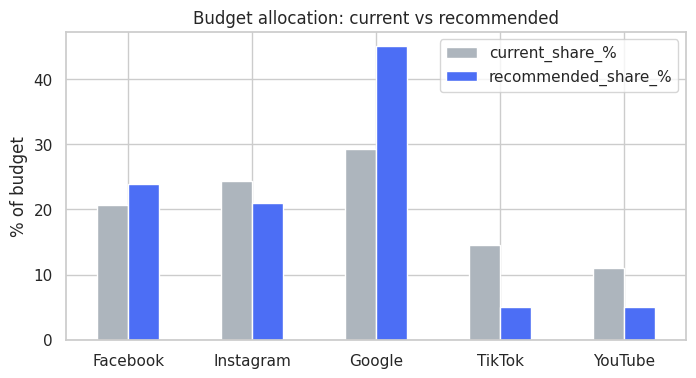

In [10]:
H = 7  # planning horizon (days)
def revenue_pred(x_total, f, H=H):
    d = x_total / H;  return H * f["a"] * d ** (1 - f["s"])

def allocate(budget, fit, H=H, lo=0.05, hi=0.45):
    a = np.array([fit[p]["a"] for p in PLAT]); s = np.array([fit[p]["s"] for p in PLAT])
    x_of = lambda lam: np.clip(H * (a*(1-s)/lam) ** (1/s), lo*budget, hi*budget)
    L, U = 1e-6, 1e6
    for _ in range(200):
        mid = np.sqrt(L*U)
        if x_of(mid).sum() > budget: L = mid
        else: U = mid
    x = x_of(np.sqrt(L*U)); x = x * budget / x.sum()
    return dict(zip(PLAT, x))

BUDGET = 1_000_000
alloc = allocate(BUDGET, fits)
cur = df.groupby("platform").spend.sum().loc[PLAT]; cur_share = cur / cur.sum()
eng = pd.DataFrame({
    "current_share_%": 100*cur_share,
    "recommended_share_%": [100*alloc[p]/BUDGET for p in PLAT],
    "spend_Rs": [alloc[p] for p in PLAT],
    "daily_spend_Rs": [alloc[p]/H for p in PLAT],
    "predicted_ROAS": [revenue_pred(alloc[p], fits[p])/alloc[p] for p in PLAT],
    "marginal_ROAS": [fits[p]["a"]*(1-fits[p]["s"])*(alloc[p]/H)**(-fits[p]["s"]) for p in PLAT],
    "inside_observed_range": [bool(fits[p]["d_p5"] <= alloc[p]/H <= fits[p]["d_p95"]) for p in PLAT]}, index=PLAT)
display(eng.round(2))
print("Recommendation for the next Rs 1,000,000 (simulated data):")
print("   " + ",  ".join(f"{p}: {alloc[p]/BUDGET:.0%}" for p in PLAT))
print(f"Predicted revenue Rs {sum(revenue_pred(alloc[p], fits[p]) for p in PLAT)/1e6:.2f}M  (blended ROAS {sum(revenue_pred(alloc[p], fits[p]) for p in PLAT)/BUDGET:.2f})")
ax = eng[["current_share_%","recommended_share_%"]].plot(kind="bar", figsize=(8, 4), color=["#adb5bd","#4c6ef5"])
ax.set(title="Budget allocation: current vs recommended", ylabel="% of budget"); plt.xticks(rotation=0); plt.show()

In [11]:
# Cross-check the optimiser with a general-purpose solver (objective in Rs million so tolerances are meaningful)
from scipy.optimize import minimize
r = minimize(lambda x: -sum(revenue_pred(x[i]*BUDGET, fits[p]) for i, p in enumerate(PLAT))/1e6, x0=[.3,.15,.3,.15,.1],
             bounds=[(.05,.45)]*5, constraints={"type":"eq","fun":lambda x: x.sum()-1}, method="SLSQP", options={"ftol":1e-12,"maxiter":500})
print("SLSQP converged:", r.success, "| max difference vs engine (percentage points):",
      round(float(np.abs(100*r.x - eng["recommended_share_%"].values).max()), 3))

SLSQP converged: True | max difference vs engine (percentage points): 0.0


## 7. Is the recommendation trustworthy? Two checks
**Check 1: held-out forecast.** Fit the curves on Jan-Sep, predict Oct-Dec platform-day revenue, compare with a naive constant-ROAS model.
**Check 2: simulated A/B test.** Re-run the simulator spending Rs 1M per week under each strategy and compare *actual* simulated revenue.
Check 2 is **circular by design**: the simulator uses the same kind of curve, so it validates the *optimiser and the curve-fitting*, not the real world.

In [12]:
train = pdays[pdays.date < "2025-10-01"]; test = pdays[pdays.date >= "2025-10-01"].copy()
ft = fit_all(train)
test["curve"] = [ft[p]["a"]*s**(1-ft[p]["s"]) for p, s in zip(test.platform, test.spend)]
const = train.groupby("platform").apply(lambda g: g.revenue.sum()/g.spend.sum(), include_groups=False)
test["const"] = test.spend * test.platform.map(const)
wape = lambda y, p: np.abs(y-p).sum()/y.sum()
print(f"Held-out WAPE (lower is better):  curve model {wape(test.revenue, test.curve):.3f}   constant-ROAS model {wape(test.revenue, test.const):.3f}")
print("Note: Oct-Dec includes the Black Friday sale window, which neither model knows about.")

sh = {"Current mix": cur_share.values, "Equal split (20% each)": np.full(5, .2),
      "ROAS-proportional": plat.ROAS.values/plat.ROAS.sum(), "Engine (caps 5-45%)": np.array([alloc[p]/BUDGET for p in PLAT])}
ab = {}
for name, s_ in sh.items():
    w = [adsim.generate_arrays(200_000, seed=100+k, daily_budget=s_*BUDGET/7)["revenue"].sum()*7/adsim.N_DAYS for k in range(5)]
    ab[name] = (np.mean(w), np.std(w, ddof=1))
ab = pd.DataFrame(ab, index=["weekly_revenue_Rs", "sd"]).T
ab["uplift_vs_current_%"] = 100*(ab.weekly_revenue_Rs/ab.loc["Current mix","weekly_revenue_Rs"]-1)
display(ab.round(1))

Held-out WAPE (lower is better):  curve model 0.176   constant-ROAS model 0.197
Note: Oct-Dec includes the Black Friday sale window, which neither model knows about.


,weekly_revenue_Rs,sd,uplift_vs_current_%
Current mix,4186736.3,28512.5,0.0
Equal split (20% each),3630752.2,20157.7,-13.3
ROAS-proportional,4657923.7,17935.7,11.3
Engine (caps 5-45%),4873800.8,24616.8,16.4


In [13]:
# Can the method recover the TRUE diminishing-returns strengths? (only checkable because the data is simulated)
est = {p: [] for p in PLAT}
for sd in range(8):
    d2 = adsim.generate(100_000, seed=500+sd); d2["date"] = pd.to_datetime(d2["date"])
    g2 = d2.groupby(["platform","date"]).agg(spend=("spend","sum"), revenue=("revenue","sum")).reset_index()
    g2 = g2[(g2.spend>0)&(g2.revenue>0)]
    for p in PLAT:
        h = g2[g2.platform == p]; est[p].append(-np.polyfit(np.log(h.spend), np.log(h.revenue/h.spend), 1)[0])
chk = pd.DataFrame({"true_s": adsim.SAT, "mean_estimate": [np.mean(est[p]) for p in PLAT], "sd": [np.std(est[p], ddof=1) for p in PLAT]}, index=PLAT)
chk["bias"] = chk.mean_estimate - chk.true_s
display(chk.round(3))

,true_s,mean_estimate,sd,bias
Facebook,0.20,0.169,0.025,-0.031
Instagram,0.30,0.293,0.023,-0.007
Google,0.15,0.155,0.017,0.005
TikTok,0.35,0.307,0.041,-0.043
YouTube,0.25,0.282,0.074,0.032


## 8. Business interpretation (Finding / Evidence / Action / Limitation)
Fill in from **your** outputs above. The structure that worked for the simulated run:

* **Finding:** Google has the best ROAS but the budget cap stops it taking everything; YouTube does not pay back its spend (ROAS below 1).
* **Evidence:** ROAS table (section 3), response curves (section 5), allocation table (section 6).
* **Action:** shift the next Rs 1M toward Google and Facebook, trim TikTok/YouTube to the minimum, and **run a real test** before moving the full amount.
* **Limitations:** simulated data; the recommended spend for several platforms is **below the range seen in the history** (see `inside_observed_range`),
  so those curves are extrapolated; the A/B check is circular; sale windows and creative fatigue are not modelled; ROAS is not profit.


- [x] Data source and provenance (simulated; assumptions stated)
- [x] 12-column data, record count, missing/duplicate checks
- [x] CTR, CPC, CPA, conversion rate, ROAS, revenue, campaign performance
- [x] 10K → 10M benchmark: Pandas vs MapReduce vs Spark, results verified identical
- [x] Budget recommendation (e.g. *Facebook x%, Instagram y%, Google z%, TikTok …*) with validation and limitations